In [1]:
# !pip install langdetect
# !pip install transformers

# Section 4 – Sentiment Analysis
Reddit comments often carry emotional tone and thematic content. In this exercise, you will explore these
aspects to enrich their understanding of text analytics.
## 1- Sentiment Analysis (classical): 
Use a pre-trained sentiment analysis model (e.g., VADER from NLTK
or HuggingFace transformers) to classify each comment in the supervised dataset as positive,
negative, or neutral.
### 1a. data loading and preprocess
Note that for sentiment analysis removing some stopwords (e.g., “not”, “never”, “no”) may
be harmful. Slightly adjust your preprocessing pipeline if you deem it useful.

In [2]:
import pandas as pd
import numpy as np
from langdetect import detect, DetectorFactory
import matplotlib.pyplot as plt
from transformers import AutoModelForSequenceClassification
#from transformers import TFAutoModelForSequenceClassification
from transformers import AutoTokenizer
from scipy.special import softmax
import csv
import urllib.request
import os  # check for file existence
import torch
import seaborn as sns
import ollama

In [3]:
# #to execute from google colab using google drive for data_supervised.csv (avoid repeated upload every time)
# from pydrive2.auth import GoogleAuth
# from pydrive2.drive import GoogleDrive
# from google.colab import auth
# from oauth2client.client import GoogleCredentials
# auth.authenticate_user()
# gauth = GoogleAuth()
# gauth.credentials = GoogleCredentials.get_application_default()
# drive = GoogleDrive(gauth)

# data = drive.CreateFile({'id':#insert here the link to file on google drive''})
# data.GetContentFile('data_supervised.csv')
# data = pd.read_csv("data_supervised.csv", encoding="utf8")

In [4]:
#for local execution
data = pd.read_csv("datasets/data_supervised.csv", encoding="utf8")

In [5]:
#quick cleaning of data
data=data.drop_duplicates()#drop duplicates
data['body'] = data['body'].str.lower()#to lowercase
data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs)
data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters (english alphabet) and whitespace
data = data[data['body'].str.strip().astype(bool)]#remove comments with only whitespace
data = data.dropna()#remove empty comments
data=data.drop_duplicates(['body']) #removing duplicates again (some rows may be identical after cleaning)

langs = []
#Note that we need a different file w.r.t. other tasks because we are not removing stops words
if not os.path.exists("datasets/unsupervised_lang_sentiment_analysis.txt"):
    DetectorFactory.seed = 0
    for text in data['body']:
        try:
            langs.append(detect(text))
        except:
            langs.append("error")

    with open("datasets/unsupervised_lang_sentiment_analysis.txt", "w") as f:
        for lang in langs:
                f.write(f"{lang}\n")
else:
    with open("datasets/unsupervised_lang_sentiment_analysis.txt") as f:#Just to avoid re-detecting languages every time
        for line in f:
            langs.append(line.strip())
data = data[pd.Series(langs, index=data.index)=='en'] #mask data to mantain only english comments

In [6]:
if not os.path.exists("datasets/data_sentiment_scores.csv"):
    task='sentiment'
    MODEL = f"cardiffnlp/twitter-roberta-base-{task}"

    tokenizer = AutoTokenizer.from_pretrained(MODEL)

    # download label mapping
    labels=[]
    mapping_link = f"https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/sentiment/mapping.txt"
    with urllib.request.urlopen(mapping_link) as f:
        html = f.read().decode('utf-8').split("\n")
        csvreader = csv.reader(html, delimiter='\t')
    labels = [row[1] for row in csvreader if len(row) > 1]

    model = AutoModelForSequenceClassification.from_pretrained(MODEL)
    model.save_pretrained(MODEL)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)

    batch_size = 64
    max_length = 256

    texts = data.loc[:,"body"].tolist()
    rows = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i : i + batch_size]
        encoded = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        with torch.no_grad():
            out = model(**encoded)
            logits = out.logits.detach().cpu().numpy()
        probs = softmax(logits, axis=1)
        for p in probs:
            rows.append(dict(zip(labels, p)))

    data_scores = pd.DataFrame(rows)
    data_scores.to_csv("datasets/data_sentiment_scores.csv")
else:
    data_scores = pd.read_csv("datasets/data_sentiment_scores.csv")
    #remove index column
    data_scores = data_scores.drop(data_scores.columns[0], axis=1)
    labels = data_scores.columns.tolist()

### 1b. What is the overall sentiment distribution across all comments?

Summary statistics of sentiment scores:
            negative        neutral       positive
count  261982.000000  261982.000000  261982.000000
mean        0.340363       0.418168       0.241469
std         0.315730       0.258450       0.306607
min         0.000716       0.004746       0.001514
25%         0.048596       0.184859       0.029401
50%         0.239488       0.419361       0.082823
75%         0.600392       0.633106       0.349744
max         0.984362       0.958402       0.993273


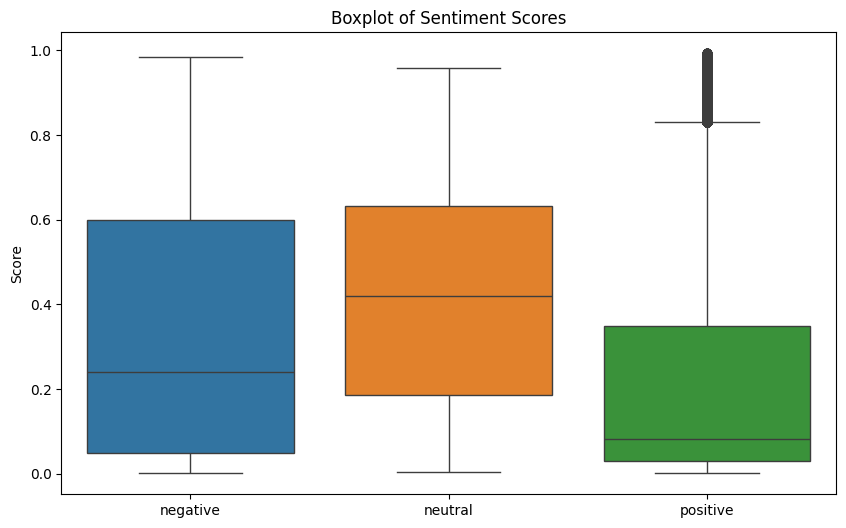

In [7]:
#sumary statistics of sentiment scores
print("Summary statistics of sentiment scores:")
print(data_scores.describe())

#boxplot of sentiment scores
plt.figure(figsize=(10, 6))
sns.boxplot(data=data_scores)
plt.title("Boxplot of Sentiment Scores")
plt.ylabel("Score")
plt.xticks()
plt.show()

### 1c. Visualize sentiment distribution per subreddit using bar charts or heatmaps.

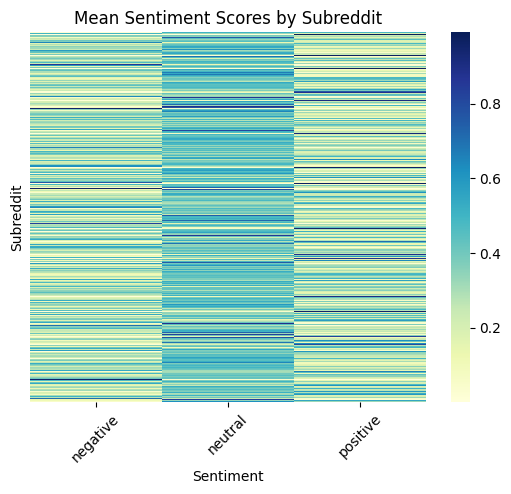

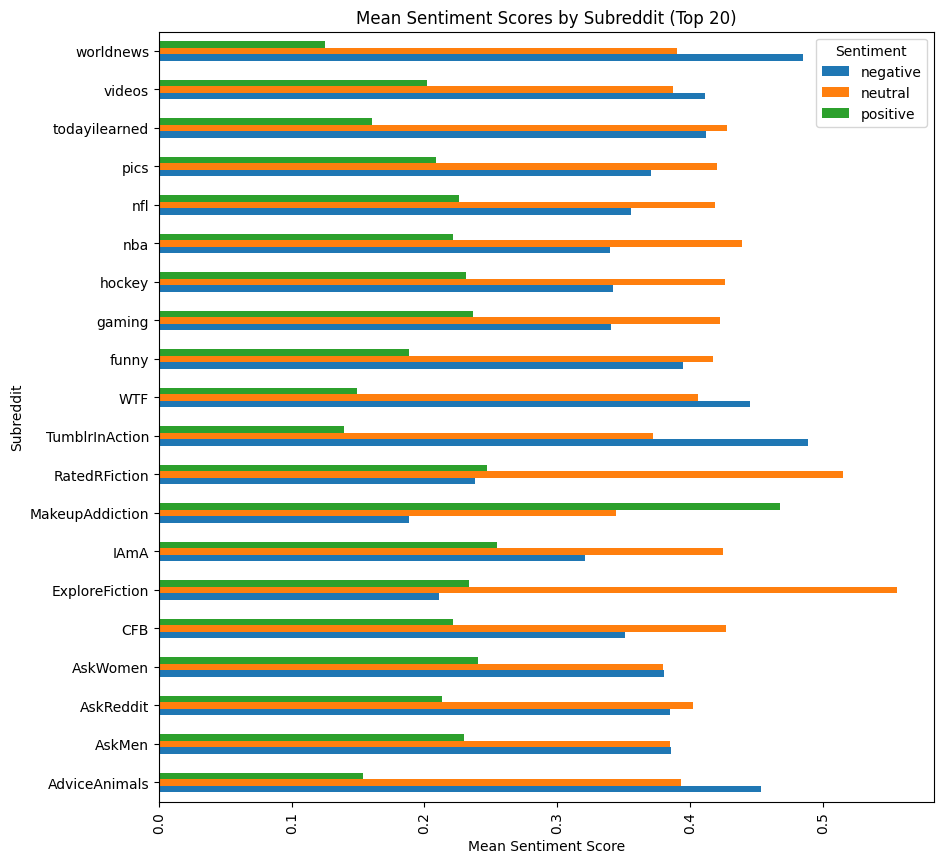

In [8]:
#attach datascores to data
data_scores.reset_index(drop=True, inplace=True)
data.reset_index(drop=True, inplace=True)
data_with_scores = pd.concat([data, data_scores], axis=1)

#group by subreddit and calculate mean sentiment scores
subreddit_sentiment = data_with_scores.groupby('subreddit')[labels].mean().reset_index()

#heatmap of mean sentiment scores by subreddit
ax = sns.heatmap(subreddit_sentiment[labels].set_index(subreddit_sentiment['subreddit']), annot=False, cmap="YlGnBu", yticklabels=False)
plt.title("Mean Sentiment Scores by Subreddit")
plt.xlabel("Sentiment")
plt.ylabel("Subreddit")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

#bar charts of mean sentiment scores by subreddit
#consider the 20 subreddits with the most comments
top_subreddits = data_with_scores['subreddit'].value_counts().nlargest(20).index
subreddit_sentiment_top = subreddit_sentiment[subreddit_sentiment['subreddit'].isin(top_subreddits)]
subreddit_sentiment_top = subreddit_sentiment_top.set_index('subreddit')
subreddit_sentiment_top.plot(kind='barh', figsize=(10, 10))
plt.title("Mean Sentiment Scores by Subreddit (Top 20)")
plt.ylabel("Subreddit")
plt.xlabel("Mean Sentiment Score")
plt.xticks(rotation=90)
plt.legend(title="Sentiment")
plt.show()

### 1d. Does sentiment correlate with gender? 
For example, do male or female users tend to post more positive or negative comments?

In [9]:
#load genders
genders = pd.read_csv("datasets/target_supervised.csv")
data_with_scores = data_with_scores.merge(genders, on='author', how='left')

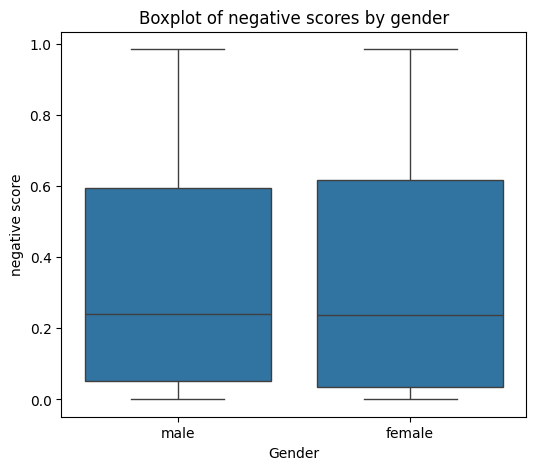

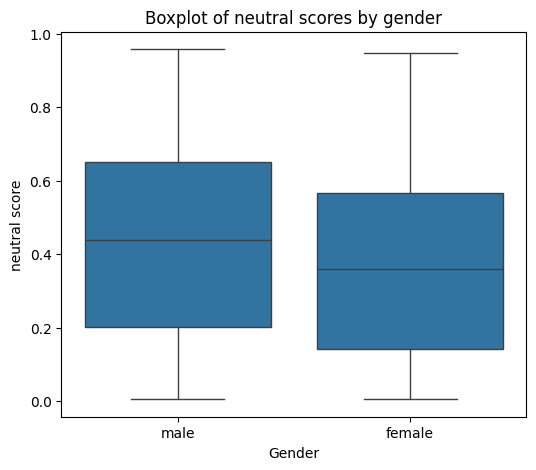

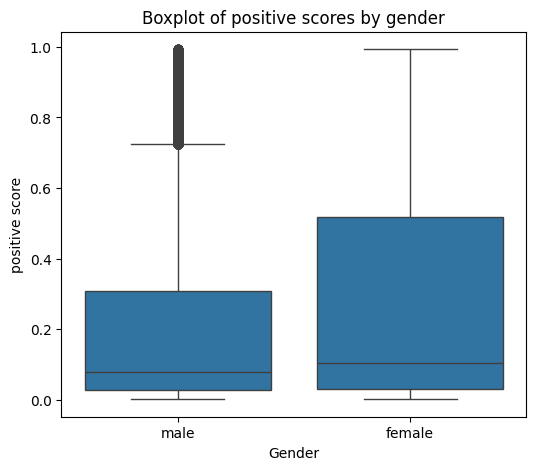

In [10]:
# box plot of sentiment scores by gender
# map numeric labels to readable categories for plotting
gender_plot_data = data_with_scores.copy()
gender_plot_data['gender'] = gender_plot_data['gender'].map({0: 'male', 1: 'female'})

gender_plot_data = gender_plot_data.dropna(subset=['gender'])

for sentiment in labels:
    plt.figure(figsize=(6, 5))
    sns.boxplot(x='gender', y=sentiment, data=gender_plot_data, order=['male', 'female'])
    plt.title(f"Boxplot of {sentiment} scores by gender")
    plt.xlabel("Gender")
    plt.ylabel(f"{sentiment} score")
    plt.show()

## 2- Integration Challenge
Combine sentiment features with your supervised learning pipeline. Does adding these features improve gender prediction performance? Why or why not?

## 3 Sentiment Analysis - LLM zero-shot
Try zero-shot classification using a (small) LLM model like tinyllama (1.1B) or qwen3:1.7b. You can use Ollama python library to download and use these open-source models.

### 3a. 
Define candidate labels ["positive", "negative", "neutral"] and develop a prompt to let the LLM classify comments and provide you with a single label.

In [11]:
def classify_sentiment(comment: str) -> str:
    prompt = f"""Classify the sentiment of the following Reddit comment.
Choose EXACTLY one label from: ["positive", "negative", "neutral"].
Reply with only the label, nothing else.

Comment: {comment}
Label:"""
    
    response = ollama.chat(
        model="qwen3:1.7b",
        messages=[{"role": "user", "content": prompt}]
    )
    label = response['message']['content'].strip().lower()
    if label not in ["positive", "negative", "neutral"]:
        label = "unknown"
        print(f"Unexpected label '{label}' for comment: {comment}")
    return label

### 3b.
Use the zero-shot classification pipeline to classify comments. Use only a small subset of the dataset (running an LLM may be resource-intensive!).

In [12]:
if not os.path.exists("datasets/zero_shot_subset.csv"):
    #Pick 10 most positive and 10 most negative comments according to cardiffnlp/twitter-roberta-base-sentiment
    #pick also 90 random comments
    zero_shot_subset = pd.concat([
        data_with_scores.sort_values(by='positive', ascending=False).head(10),
        data_with_scores.sort_values(by='negative', ascending=False).head(10),
        data_with_scores.sample(90, random_state=42)
    ]).drop_duplicates(subset='body').reset_index(drop=True)

    comments = zero_shot_subset['body'].tolist()
    labels_llm = []
    for comment in comments:
        labels_llm.append(classify_sentiment(comment))
        print(f"Comment: {comment}\nLLM Sentiment: {labels_llm[-1]}\n")

    zero_shot_subset['llm_sentiment'] = labels_llm
    zero_shot_subset.to_csv("datasets/zero_shot_subset.csv", index=False)
else:
    zero_shot_subset = pd.read_csv("datasets/zero_shot_subset.csv")

### 3c. 
For the reduced dataset, manually inspect 50-100 comments and label them ("positive",
"negative", "neutral"). Choose if taking the comments from different subreddit or the same
one, motivate your reasoning. Compare the zero-shot predictions with the sentiment
analysis model predictions and your labels. According to this small-scale experiment which
methodology seems the most promising?

In [13]:
#comments were taken from
if not os.path.exists("datasets/manual_labels.csv"):
    #Store csv with empty labels so we can manually fill it
    sample = zero_shot_subset.tail(50)[['body']]
    sample['your_label'] = ''
    sample.to_csv('datasets/manual_labels.csv', index=False)

#Read manually labeled data
manual_labels = pd.read_csv("datasets/manual_labels.csv")
#strip whitespace from labels
manual_labels['your_label'] = manual_labels['your_label'].str.strip().str.lower()

#check if all comments are labeled as one of ["positive", "negative", "neutral"]
valid_labels = ["positive", "negative", "neutral"]
if not all(label in valid_labels for label in manual_labels['your_label']):
    print("Warning: Some comments have invalid labels.")
    #for all invalid labels, print the comment and the invalid label
    for index, row in manual_labels.iterrows():
        if row['your_label'] not in valid_labels:
            print(f"Comment: {row['body']}\nInvalid Label: {row['your_label']}\n")
            input("Please fix the invalid label and press Enter to continue...")
    
#now take max from cardiffnlp/twitter-roberta-base-sentiment as predicted label (later we may also analyze the scores)
def get_predicted_label(row):
    scores = row[labels].values
    max_index = np.argmax(scores)
    return labels[max_index]

#add labels from cardiffnlp/twitter-roberta-base-sentiment and from LLM to manual_labels dataframe
manual_labels['twitter_roberta_label'] = zero_shot_subset.tail(50).apply(get_predicted_label, axis=1).values
manual_labels['llm_label'] = zero_shot_subset.tail(50)['llm_sentiment'].values
manual_labels[labels] = zero_shot_subset.tail(50)[labels].values

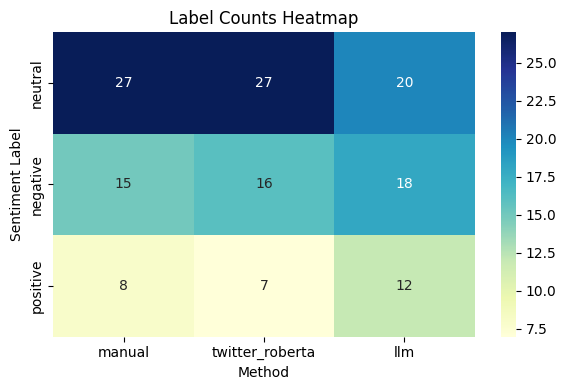

In [14]:
# create a table with counts of each label for manual, twitter_roberta and llm labels
label_counts = pd.DataFrame({
    'manual': manual_labels['your_label'].value_counts(),
    'twitter_roberta': manual_labels['twitter_roberta_label'].value_counts(),
    'llm': manual_labels['llm_label'].value_counts(),
}).fillna(0).astype(int)

plt.figure(figsize=(6, 4))
sns.heatmap(label_counts, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title('Label Counts Heatmap')
plt.xlabel('Method')
plt.ylabel('Sentiment Label')
plt.tight_layout()
plt.show()

In [15]:
#Difference with manual labels for twitter_roberta and llm
diff_counts = pd.DataFrame({
    'twitter_roberta': (manual_labels['your_label'] != manual_labels['twitter_roberta_label']).sum(),
    'llm': (manual_labels['your_label'] != manual_labels['llm_label']).sum(),
}, index=['count'])
print("Number of disagreements with manual labels:")
print(diff_counts)

#got twitter_roberta we can also analyze the scores by label
#we want to check if the labels that disagree with manual labels have lower scores for the predicted label compared to those that agree
#add a column to manual_labels with the score of the predicted label
def get_predicted_score(row):
    scores = row[labels].values
    max_index = np.argmax(scores)
    return scores[max_index]

manual_labels['predicted_score'] = zero_shot_subset.tail(50).apply(get_predicted_score, axis=1).values

disagree_scores_mean = 0
agree_scores_mean = 0
disagree_count = 0
agree_count = 0
for index, row in manual_labels.iterrows():
    if row['your_label'] != row['twitter_roberta_label']:
        disagree_scores_mean += row['predicted_score']
        disagree_count += 1
        #print(f"Disagreement at index {index}:")
        #print(f"Comment: {row['body']}")
        #print(f"Manual Label: {row['your_label']}, Twitter Roberta Label: {row['twitter_roberta_label']}, Score: {row['predicted_score']}\n") 
    else:
        agree_scores_mean += row['predicted_score']
        agree_count += 1

if disagree_count > 0:
    disagree_scores_mean /= disagree_count

if agree_count > 0:
    agree_scores_mean /= agree_count

print(f"Average score for disagreements: {disagree_scores_mean}")
print(f"Average score for agreements: {agree_scores_mean}")

Number of disagreements with manual labels:
       twitter_roberta  llm
count               12   19
Average score for disagreements: 0.6343314475
Average score for agreements: 0.7300527168421053
